# Problem 3: Data Augmentation as Inductive Bias



> **Setup.** This notebook expects the crowd-density images at `data/data/{high_new1,low_new1,medium_new1}/` (see [`DATA.md`](../DATA.md)). The dataset is **not** included in this repository. The original `!unzip data.zip -d data` cell is kept for Colab use; skip it if the folders are already in place.
>
> **Naming note.** The corruption called `jpeg_noise` in the code adds Gaussian pixel noise (std 0.08); it is *not* JPEG compression. It keeps its original name so the saved outputs match the code. The corruption transforms are random at evaluation time, so re-running gives slightly different numbers.

In [1]:
!unzip data.zip -d data

In [2]:
!pip install seaborn

In [3]:
import copy
import math
import random
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.datasets import ImageFolder

sns.set_theme(style='whitegrid')


## Configuration

In [4]:
SEED = 42
DATA_ROOT = Path('data/data')
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASS_NAMES = ['low', 'medium', 'high']
CORRUPTION_TYPES = ['gaussian_blur', 'jpeg_noise', 'brightness_shift', 'occlusion']
FAILURE_EXAMPLES_PER_AUG = 4

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print(f'Using device: {DEVICE}')


Using device: cuda


## Dataset And Augmentation Design

We use one shared train/validation/test split for every augmentation strategy so the comparison stays controlled. The training transformations differ, but the model architecture, optimizer, split, and evaluation protocol stay the same.


In [5]:
def infer_class_from_folder(folder_name):
    name = folder_name.lower()
    if 'low' in name:
        return 'low'
    if 'medium' in name or 'mid' in name:
        return 'medium'
    if 'high' in name:
        return 'high'
    raise ValueError(f'Could not infer class from folder name: {folder_name}')


def load_rgb_image(path):
    with Image.open(path) as image:
        return image.convert('RGB')


def is_valid_image(path):
    try:
        with Image.open(path) as image:
            image.verify()
        return True
    except Exception as exc:
        print(f'Skipping unreadable image: {path} ({exc})')
        return False


def build_folder_remap(class_to_idx):
    remap = {}
    for folder_name, folder_idx in class_to_idx.items():
        remap[folder_idx] = CLASS_NAMES.index(infer_class_from_folder(folder_name))
    return remap


class CutoutTransform:
    def __init__(self, scale=(0.08, 0.18), ratio=(0.8, 1.2), value=0.0):
        self.random_erasing = transforms.RandomErasing(p=1.0, scale=scale, ratio=ratio, value=value)

    def __call__(self, tensor):
        return self.random_erasing(tensor)


NORMALIZE = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

TRAIN_AUGMENTATIONS = {
    'baseline': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        NORMALIZE,
    ]),
    'rotation': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomRotation(25),
        transforms.ToTensor(),
        NORMALIZE,
    ]),
    'crop': transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
        transforms.ToTensor(),
        NORMALIZE,
    ]),
    'color_jitter': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.35, hue=0.08),
        transforms.ToTensor(),
        NORMALIZE,
    ]),
    'cutout': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        CutoutTransform(),
        NORMALIZE,
    ]),
}

CLEAN_EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    NORMALIZE,
])

CORRUPTION_TRANSFORMS = {
    'gaussian_blur': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.GaussianBlur(kernel_size=5, sigma=(1.0, 2.0)),
        transforms.ToTensor(),
        NORMALIZE,
    ]),
    'jpeg_noise': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Lambda(lambda x: torch.clamp(x + 0.08 * torch.randn_like(x), 0.0, 1.0)),
        NORMALIZE,
    ]),
    'brightness_shift': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ColorJitter(brightness=0.45, contrast=0.2),
        transforms.ToTensor(),
        NORMALIZE,
    ]),
    'occlusion': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        CutoutTransform(scale=(0.15, 0.28), ratio=(0.9, 1.1), value=0.0),
        NORMALIZE,
    ]),
}


class CrowdDataset(Dataset):
    def __init__(self, base_dataset, indices, transform, folder_remap):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform
        self.folder_remap = folder_remap

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        while True:
            sample_idx = self.indices[idx]
            path, label = self.base_dataset.samples[sample_idx]
            try:
                image = load_rgb_image(path)
                tensor = self.transform(image)
                return {
                    'image': tensor,
                    'label': self.folder_remap[label],
                    'path': path,
                    'sample_idx': sample_idx,
                }
            except Exception as exc:
                print(f'Skipping unreadable image during dataset fetch: {path} ({exc})')
                idx = (idx + 1) % len(self.indices)


def collate_batch(batch):
    return {
        'images': torch.stack([item['image'] for item in batch]),
        'labels': torch.tensor([item['label'] for item in batch], dtype=torch.long),
        'paths': [item['path'] for item in batch],
        'sample_idx': [item['sample_idx'] for item in batch],
    }


def filter_valid_indices(base_dataset, indices):
    valid_indices = []
    skipped = []
    for idx in indices:
        path, _ = base_dataset.samples[idx]
        if is_valid_image(path):
            valid_indices.append(idx)
        else:
            skipped.append(path)
    return valid_indices, skipped


def make_splits(data_root):
    base_dataset = ImageFolder(root=str(data_root))
    folder_remap = build_folder_remap(base_dataset.class_to_idx)
    labels = [folder_remap[label] for _, label in base_dataset.samples]
    idx_all = np.arange(len(base_dataset))

    idx_trainval, idx_test = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=labels,
        random_state=SEED,
    )

    labels_tv = [labels[i] for i in idx_trainval]
    idx_train, idx_val = train_test_split(
        idx_trainval,
        test_size=0.176,
        stratify=labels_tv,
        random_state=SEED,
    )

    idx_train, skipped_train = filter_valid_indices(base_dataset, list(idx_train))
    idx_val, skipped_val = filter_valid_indices(base_dataset, list(idx_val))
    idx_test, skipped_test = filter_valid_indices(base_dataset, list(idx_test))

    skipped = {
        'train': skipped_train,
        'val': skipped_val,
        'test': skipped_test,
    }
    return base_dataset, folder_remap, labels, idx_train, idx_val, idx_test, skipped


def make_loader(base_dataset, indices, transform, folder_remap, shuffle=False):
    dataset = CrowdDataset(base_dataset, indices, transform, folder_remap)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        collate_fn=collate_batch,
    )


def class_distribution(indices, labels):
    counts = np.bincount([labels[idx] for idx in indices], minlength=len(CLASS_NAMES))
    return pd.DataFrame({
        'class_name': CLASS_NAMES,
        'count': counts,
        'fraction': counts / counts.sum(),
    })


## Model, Training, And Evaluation Helpers

Every augmentation strategy uses the same pretrained ResNet18 backbone, optimizer, batch size, number of epochs, and data split. That keeps the comparison focused on augmentation as the only deliberate change.


In [6]:
def build_model(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(DEVICE)


def class_weights_from_indices(indices, labels):
    counts = np.bincount([labels[idx] for idx in indices], minlength=len(CLASS_NAMES))
    counts[counts == 0] = 1
    return torch.tensor(1.0 / counts, dtype=torch.float32, device=DEVICE)


def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    preds, labels = [], []

    for batch in loader:
        images = batch['images'].to(DEVICE)
        targets = batch['labels'].to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * targets.size(0)
        preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
        labels.extend(targets.detach().cpu().tolist())

    return {
        'loss': total_loss / len(loader.dataset),
        'acc': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
    }


@torch.no_grad()
def evaluate_loader(model, loader, criterion=None):
    model.eval()
    losses = []
    preds, labels, probs, paths = [], [], [], []

    for batch in loader:
        images = batch['images'].to(DEVICE)
        targets = batch['labels'].to(DEVICE)

        logits = model(images)
        batch_probs = torch.softmax(logits, dim=1)

        if criterion is not None:
            losses.append(criterion(logits, targets).item() * targets.size(0))

        preds.extend(logits.argmax(dim=1).cpu().tolist())
        labels.extend(targets.cpu().tolist())
        probs.extend(batch_probs.cpu().tolist())
        paths.extend(batch['paths'])

    metrics = {
        'acc': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
        'labels': labels,
        'preds': preds,
        'probs': probs,
        'paths': paths,
        'report': classification_report(labels, preds, target_names=CLASS_NAMES, zero_division=0, output_dict=True),
    }

    if criterion is not None:
        metrics['loss'] = sum(losses) / len(loader.dataset)

    return metrics


def fit_model(model, train_loader, val_loader, train_indices, labels):
    weights = class_weights_from_indices(train_indices, labels)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    history = []

    for epoch in range(EPOCHS):
        train_metrics = train_epoch(model, train_loader, optimizer, criterion)
        val_metrics = evaluate_loader(model, val_loader, criterion=criterion)

        history.append({
            'epoch': epoch + 1,
            'train_loss': train_metrics['loss'],
            'train_acc': train_metrics['acc'],
            'train_macro_f1': train_metrics['macro_f1'],
            'val_loss': val_metrics['loss'],
            'val_acc': val_metrics['acc'],
            'val_macro_f1': val_metrics['macro_f1'],
            'overfit_gap': train_metrics['acc'] - val_metrics['acc'],
        })

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"train_acc={train_metrics['acc']:.4f} | val_acc={val_metrics['acc']:.4f} | "
            f"train_f1={train_metrics['macro_f1']:.4f} | val_f1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics['acc'] > best_val_acc:
            best_val_acc = val_metrics['acc']
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return pd.DataFrame(history), criterion


def plot_training_histories(history_by_aug):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for aug_name, history_df in history_by_aug.items():
        axes[0].plot(history_df['epoch'], history_df['val_acc'], marker='o', label=aug_name)
        axes[1].plot(history_df['epoch'], history_df['overfit_gap'], marker='o', label=aug_name)

    axes[0].set_title('Validation Accuracy by Augmentation')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Validation Accuracy')
    axes[0].legend(fontsize=8)

    axes[1].set_title('Overfitting Gap by Augmentation')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Train Accuracy - Validation Accuracy')
    axes[1].axhline(0.0, color='black', linewidth=1, alpha=0.5)
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


def plot_confusion(labels, preds, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()


## Augmentation-Performance Matrix And Failure Analysis Helpers

We evaluate each trained model on a clean test set and on multiple corrupted test sets. That lets us see whether the augmentation improves clean recognition, robustness, or both.


In [7]:
def evaluate_all_views(model, criterion, clean_loader, corruption_loaders):
    results = {}
    results['clean'] = evaluate_loader(model, clean_loader, criterion=criterion)
    for name, loader in corruption_loaders.items():
        results[name] = evaluate_loader(model, loader, criterion=criterion)
    return results


def build_performance_matrix(aug_results):
    rows = []
    for aug_name, bundle in aug_results.items():
        clean_acc = bundle['eval_results']['clean']['acc']
        clean_f1 = bundle['eval_results']['clean']['macro_f1']
        corruption_accs = [bundle['eval_results'][name]['acc'] for name in CORRUPTION_TYPES]
        avg_corrupt_acc = float(np.mean(corruption_accs))
        robustness_gap = clean_acc - avg_corrupt_acc
        rows.append({
            'augmentation': aug_name,
            'best_val_acc': bundle['history_df']['val_acc'].max(),
            'clean_acc': clean_acc,
            'clean_macro_f1': clean_f1,
            'gaussian_blur_acc': bundle['eval_results']['gaussian_blur']['acc'],
            'jpeg_noise_acc': bundle['eval_results']['jpeg_noise']['acc'],
            'brightness_shift_acc': bundle['eval_results']['brightness_shift']['acc'],
            'occlusion_acc': bundle['eval_results']['occlusion']['acc'],
            'avg_corrupt_acc': avg_corrupt_acc,
            'robustness_gap': robustness_gap,
            'time_sec': bundle['time_sec'],
        })
    return pd.DataFrame(rows).sort_values(['avg_corrupt_acc', 'clean_acc'], ascending=False).reset_index(drop=True)


def plot_performance_dashboard(matrix_df):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    order = matrix_df.sort_values('avg_corrupt_acc', ascending=False)['augmentation']

    sns.barplot(data=matrix_df, x='augmentation', y='clean_acc', order=order, ax=axes[0, 0], palette='Blues_d')
    axes[0, 0].set_title('Clean Accuracy')
    axes[0, 0].set_xlabel('')
    axes[0, 0].set_ylabel('Accuracy')

    sns.barplot(data=matrix_df, x='augmentation', y='avg_corrupt_acc', order=order, ax=axes[0, 1], palette='Greens_d')
    axes[0, 1].set_title('Average Corrupted Accuracy')
    axes[0, 1].set_xlabel('')
    axes[0, 1].set_ylabel('Accuracy')

    sns.barplot(data=matrix_df, x='augmentation', y='robustness_gap', order=order, ax=axes[1, 0], palette='Oranges_d')
    axes[1, 0].set_title('Robustness Gap')
    axes[1, 0].set_xlabel('')
    axes[1, 0].set_ylabel('Clean Accuracy - Avg Corrupt Accuracy')
    axes[1, 0].axhline(0.0, color='black', linewidth=1, alpha=0.5)

    corruption_cols = ['gaussian_blur_acc', 'jpeg_noise_acc', 'brightness_shift_acc', 'occlusion_acc']
    heatmap_df = matrix_df.set_index('augmentation')[corruption_cols]
    sns.heatmap(heatmap_df, annot=True, fmt='.3f', cmap='mako', ax=axes[1, 1])
    axes[1, 1].set_title('Augmentation-Performance Matrix')
    axes[1, 1].set_xlabel('Corrupted Test View')
    axes[1, 1].set_ylabel('Augmentation')

    for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
        ax.tick_params(axis='x', rotation=20)

    plt.tight_layout()
    plt.show()


def build_long_corruption_table(matrix_df):
    long_df = matrix_df.melt(
        id_vars=['augmentation', 'clean_acc', 'avg_corrupt_acc', 'robustness_gap'],
        value_vars=['gaussian_blur_acc', 'jpeg_noise_acc', 'brightness_shift_acc', 'occlusion_acc'],
        var_name='corruption',
        value_name='accuracy',
    )
    long_df['corruption'] = long_df['corruption'].str.replace('_acc', '', regex=False)
    return long_df


def plot_corruption_lines(long_df):
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=long_df, x='corruption', y='accuracy', hue='augmentation', marker='o')
    plt.title('Per-Corruption Accuracy by Augmentation')
    plt.xlabel('Corruption Type')
    plt.ylabel('Accuracy')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


def collect_failure_cases(model, loader, top_k=FAILURE_EXAMPLES_PER_AUG):
    model.eval()
    rows = []

    with torch.no_grad():
        for batch in loader:
            images = batch['images'].to(DEVICE)
            targets = batch['labels'].to(DEVICE)
            logits = model(images)
            probs = torch.softmax(logits, dim=1)
            preds = logits.argmax(dim=1)

            for i in range(len(targets)):
                if preds[i] != targets[i]:
                    rows.append({
                        'path': batch['paths'][i],
                        'true_label': int(targets[i].item()),
                        'pred_label': int(preds[i].item()),
                        'confidence': float(probs[i, preds[i]].item()),
                        'margin_error': float(probs[i, preds[i]].item() - probs[i, targets[i]].item()),
                    })

    if not rows:
        return pd.DataFrame(columns=['path', 'true_label', 'pred_label', 'confidence', 'margin_error'])

    return pd.DataFrame(rows).sort_values(['margin_error', 'confidence'], ascending=False).head(top_k).reset_index(drop=True)


def show_failure_examples(example_df, title):
    if example_df.empty:
        print(f'No failures available for {title}.')
        return

    cols = min(len(example_df), 4)
    fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 4))
    if cols == 1:
        axes = [axes]

    for ax, row in zip(axes, example_df.to_dict('records')):
        image = load_rgb_image(row['path']).resize((IMAGE_SIZE, IMAGE_SIZE))
        ax.imshow(image)
        ax.axis('off')
        ax.set_title(
            f"true={CLASS_NAMES[int(row['true_label'])]}\n"
            f"pred={CLASS_NAMES[int(row['pred_label'])]}\n"
            f"conf={row['confidence']:.2f}"
        )

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def summarize_failure_modes(example_df):
    if example_df.empty:
        return pd.DataFrame(columns=['true_class', 'pred_class', 'count'])
    summary = (
        example_df.assign(
            true_class=example_df['true_label'].map(lambda x: CLASS_NAMES[int(x)]),
            pred_class=example_df['pred_label'].map(lambda x: CLASS_NAMES[int(x)]),
        )
        .groupby(['true_class', 'pred_class'])
        .size()
        .reset_index(name='count')
        .sort_values('count', ascending=False)
    )
    return summary


## Run Experiment

This final block trains one identical CNN per augmentation strategy, evaluates each one on clean and corrupted test views, and displays the full Problem 3 deliverables in the notebook.


Skipping unreadable image: data/data/high_new1/1894_2.png (cannot identify image file 'data/data/high_new1/1894_2.png')
Dataset folders: {'high_new1': 0, 'low_new1': 1, 'medium_new1': 2}
Train / Val / Test: 1332 285 285
Skipped unreadable files: {'train': 0, 'val': 0, 'test': 1}
Usable split class distributions: train / val / test


,class_name,count,fraction
0,low,618,0.4640
1,medium,403,0.3026
2,high,311,0.2335


,class_name,count,fraction
0,low,132,0.4632
1,medium,86,0.3018
2,high,67,0.2351


,class_name,count,fraction
0,low,132,0.4632
1,medium,87,0.3053
2,high,66,0.2316



===== Training with baseline =====
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


... (13 outputs left out)

,epoch,train_loss,train_acc,train_macro_f1,val_loss,val_acc,val_macro_f1,overfit_gap
0,1,0.4582,0.8371,0.8289,0.2019,0.9018,0.9012,-0.0647
1,2,0.1318,0.9602,0.9588,0.1542,0.9474,0.9492,0.0128
2,3,0.0547,0.9835,0.9834,0.1536,0.9404,0.9416,0.0431
3,4,0.0297,0.9932,0.9929,0.1438,0.9439,0.9450,0.0494
4,5,0.0372,0.9910,0.9900,0.1408,0.9544,0.9528,0.0366


,precision,recall,f1-score,support
low,0.9552,0.9697,0.9624,132.0000
medium,0.9302,0.9195,0.9249,87.0000
high,0.9846,0.9697,0.9771,66.0000
accuracy,0.9544,0.9544,0.9544,0.9544
macro avg,0.9567,0.9530,0.9548,285.0000
weighted avg,0.9544,0.9544,0.9543,285.0000



Augmentation-performance matrix


,augmentation,best_val_acc,clean_acc,clean_macro_f1,gaussian_blur_acc,jpeg_noise_acc,brightness_shift_acc,occlusion_acc,avg_corrupt_acc,robustness_gap,time_sec
0,cutout,0.9544,0.9544,0.9548,0.8947,0.7789,0.9544,0.9368,0.8912,0.0632,135.25
1,crop,0.9509,0.9439,0.9409,0.8596,0.8842,0.9439,0.8667,0.8886,0.0553,142.57
2,color_jitter,0.9579,0.9509,0.9477,0.8702,0.8070,0.9544,0.9088,0.8851,0.0658,168.75
3,rotation,0.9509,0.9228,0.9212,0.8211,0.9018,0.9263,0.8702,0.8798,0.0430,134.97
4,baseline,0.9544,0.9404,0.9394,0.8596,0.7860,0.9404,0.8281,0.8535,0.0868,155.20


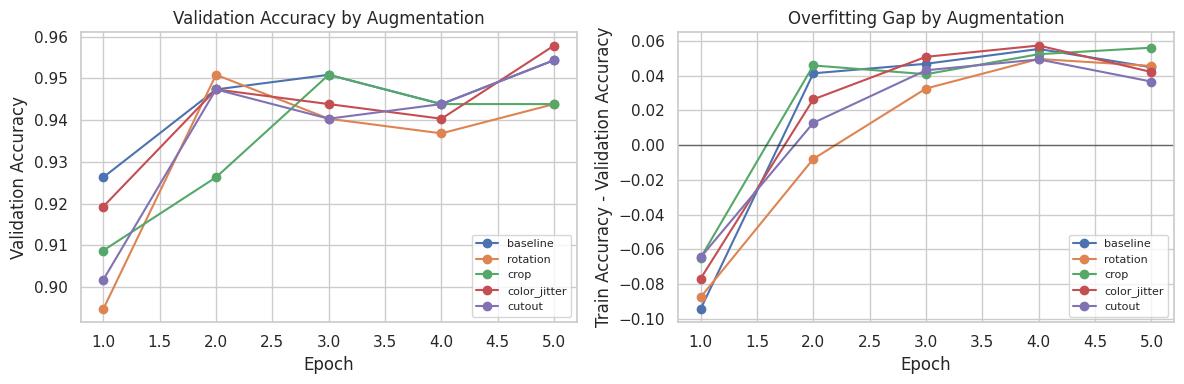

/tmp/ipykernel_5498/3728165048.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=matrix_df, x='augmentation', y='clean_acc', order=order, ax=axes[0, 0], palette='Blues_d')
/tmp/ipykernel_5498/3728165048.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=matrix_df, x='augmentation', y='avg_corrupt_acc', order=order, ax=axes[0, 1], palette='Greens_d')
/tmp/ipykernel_5498/3728165048.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=matrix_df, x='augmentation', y='robustness_gap', order=order, ax=axes[1, 0], palette='Orang

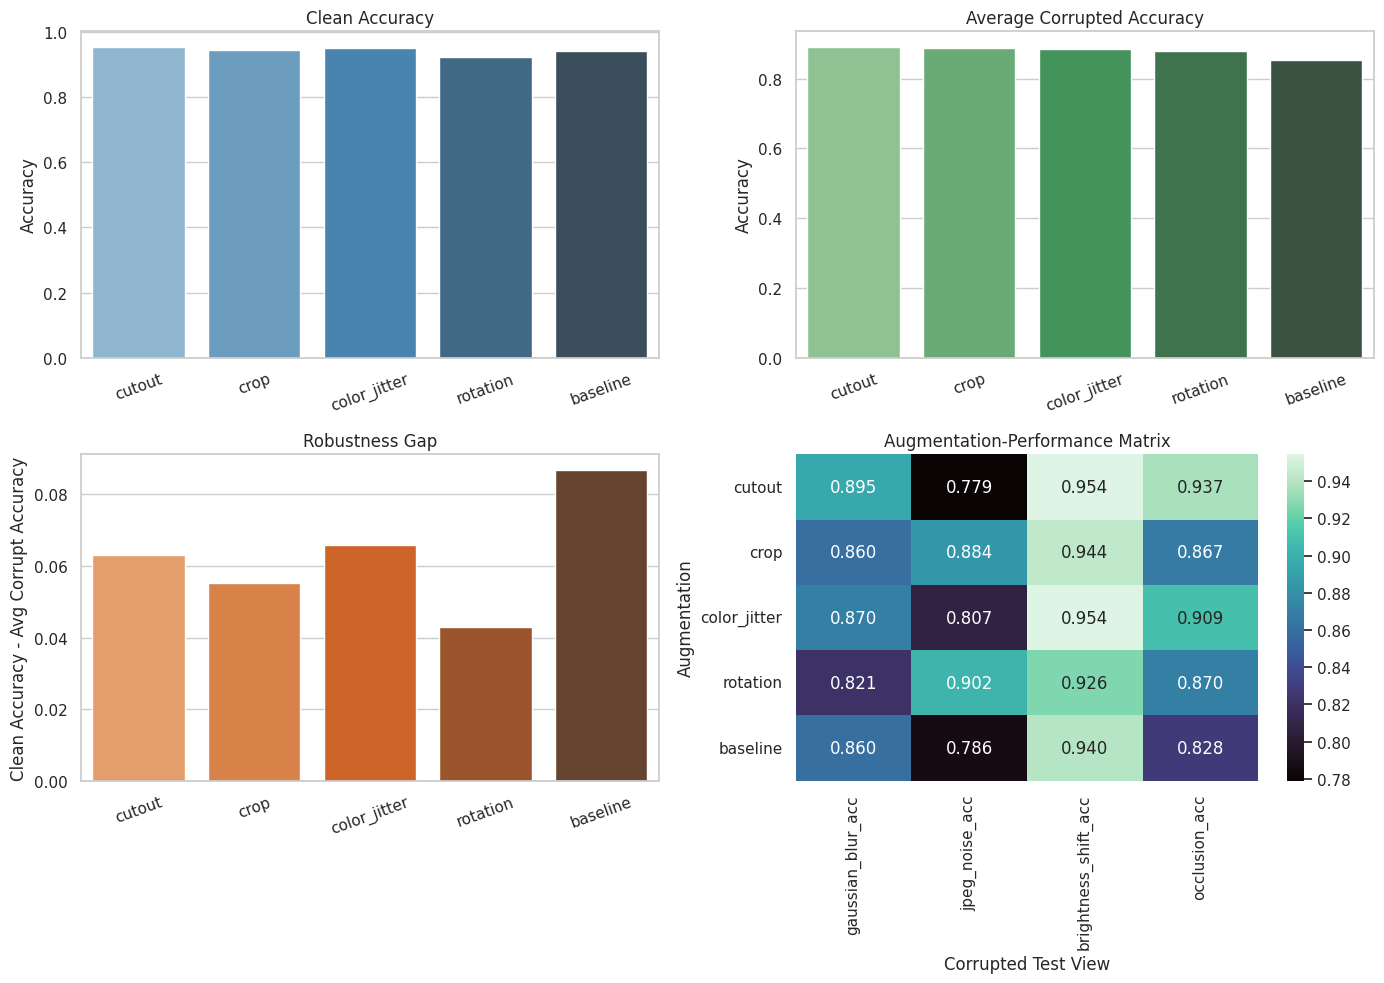

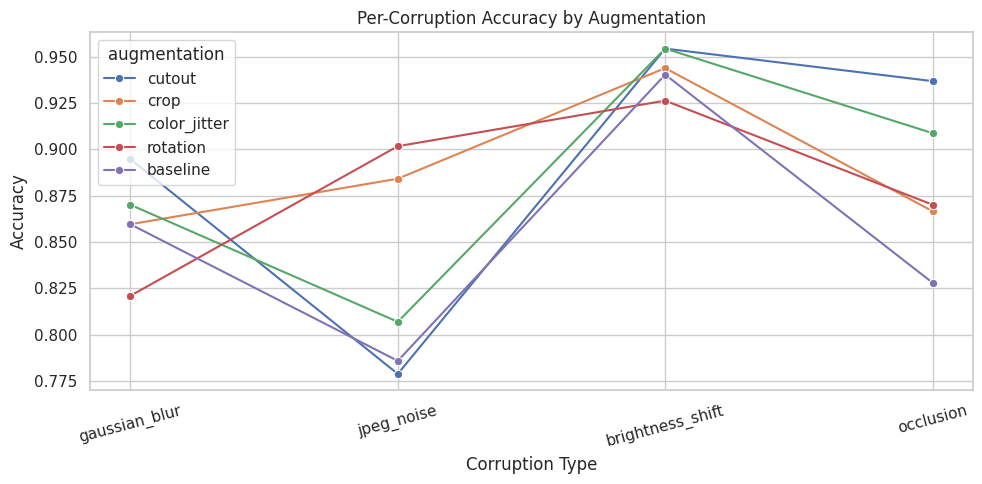

Best clean accuracy augmentation: cutout
Best average corrupted accuracy augmentation: cutout
Smallest robustness gap augmentation: rotation

Clean-test confusion matrix for best robust augmentation


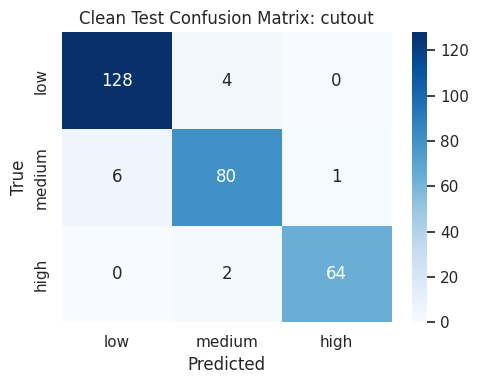


Classification reports on gaussian_blur


,augmentation,accuracy,macro_f1
4,cutout,0.8947,0.8969
3,color_jitter,0.8702,0.8575
0,baseline,0.8596,0.8524
2,crop,0.8596,0.8663
1,rotation,0.8211,0.8243



Classification reports on jpeg_noise


,augmentation,accuracy,macro_f1
1,rotation,0.9018,0.8971
2,crop,0.8842,0.8856
3,color_jitter,0.8070,0.7766
0,baseline,0.7860,0.7646
4,cutout,0.7789,0.7606



Classification reports on brightness_shift


,augmentation,accuracy,macro_f1
4,cutout,0.9544,0.9524
3,color_jitter,0.9544,0.9546
2,crop,0.9439,0.9409
0,baseline,0.9404,0.9389
1,rotation,0.9263,0.9235


... (15 outputs left out)

,path,true_label,pred_label,confidence,margin_error
0,data/data/low_new1/97_0.jpg,0,1,0.998759,0.997758
1,data/data/medium_new1/1434_1.png,1,0,0.991255,0.985716
2,data/data/medium_new1/1089_1.jpg,1,0,0.991371,0.982853
3,data/data/medium_new1/1445_1.jpg,1,0,0.971273,0.962222


,true_class,pred_class,count
1,medium,low,3
0,low,medium,1


Interpretation summary:
Best clean accuracy came from: cutout
Best corruption robustness came from: cutout
Smallest clean-to-corrupt gap came from: rotation
Augmentations that improve corrupted accuracy without hurting clean accuracy the most are the strongest evidence for useful invariance learning.


{'performance_matrix':    augmentation  best_val_acc  clean_acc  clean_macro_f1  gaussian_blur_acc  \
 0        cutout      0.954386   0.954386        0.954787           0.894737   
 1          crop      0.950877   0.943860        0.940850           0.859649   
 2  color_jitter      0.957895   0.950877        0.947742           0.870175   
 3      rotation      0.950877   0.922807        0.921175           0.821053   
 4      baseline      0.954386   0.940351        0.939417           0.859649   
 
    jpeg_noise_acc  brightness_shift_acc  occlusion_acc  avg_corrupt_acc  \
 0        0.778947              0.954386       0.936842         0.891228   
 1        0.884211              0.943860       0.866667         0.888596   
 2        0.807018              0.954386       0.908772         0.885088   
 3        0.901754              0.926316       0.870175         0.879825   
 4        0.785965              0.940351       0.828070         0.853509   
 
    robustness_gap  time_sec  
 0     

In [8]:
base_dataset, folder_remap, labels, idx_train, idx_val, idx_test, skipped_files = make_splits(DATA_ROOT)
print('Dataset folders:', base_dataset.class_to_idx)
print('Train / Val / Test:', len(idx_train), len(idx_val), len(idx_test))
print('Skipped unreadable files:', {split: len(paths) for split, paths in skipped_files.items()})
print('Usable split class distributions: train / val / test')
display(class_distribution(idx_train, labels).round(4))
display(class_distribution(idx_val, labels).round(4))
display(class_distribution(idx_test, labels).round(4))

clean_test_loader = make_loader(base_dataset, idx_test, CLEAN_EVAL_TRANSFORM, folder_remap, shuffle=False)
corruption_loaders = {
    name: make_loader(base_dataset, idx_test, transform, folder_remap, shuffle=False)
    for name, transform in CORRUPTION_TRANSFORMS.items()
}

experiment_results = {}
failure_examples_by_aug = {}
failure_mode_tables = {}

for aug_name, train_transform in TRAIN_AUGMENTATIONS.items():
    print(f'\n===== Training with {aug_name} =====')
    model = build_model(num_classes=len(CLASS_NAMES))
    train_loader = make_loader(base_dataset, idx_train, train_transform, folder_remap, shuffle=True)
    val_loader = make_loader(base_dataset, idx_val, CLEAN_EVAL_TRANSFORM, folder_remap, shuffle=False)

    start_time = time.time()
    history_df, criterion = fit_model(model, train_loader, val_loader, idx_train, labels)
    elapsed = time.time() - start_time

    eval_results = evaluate_all_views(model, criterion, clean_test_loader, corruption_loaders)
    experiment_results[aug_name] = {
        'model': model,
        'history_df': history_df,
        'criterion': criterion,
        'eval_results': eval_results,
        'time_sec': round(elapsed, 2),
    }

    occlusion_failures = collect_failure_cases(model, corruption_loaders['occlusion'])
    failure_examples_by_aug[aug_name] = occlusion_failures
    failure_mode_tables[aug_name] = summarize_failure_modes(occlusion_failures)

    print(f'Training time: {elapsed:.1f}s')
    display(history_df.round(4))
    clean_report_df = pd.DataFrame(eval_results['clean']['report']).T
    display(clean_report_df.round(4))

performance_matrix = build_performance_matrix(experiment_results)
long_corruption_df = build_long_corruption_table(performance_matrix)

print('\nAugmentation-performance matrix')
display(performance_matrix.round(4))
plot_training_histories({k: v['history_df'] for k, v in experiment_results.items()})
plot_performance_dashboard(performance_matrix)
plot_corruption_lines(long_corruption_df)

best_clean_aug = performance_matrix.sort_values('clean_acc', ascending=False).iloc[0]['augmentation']
best_robust_aug = performance_matrix.sort_values('avg_corrupt_acc', ascending=False).iloc[0]['augmentation']
smallest_gap_aug = performance_matrix.sort_values('robustness_gap', ascending=True).iloc[0]['augmentation']

print(f'Best clean accuracy augmentation: {best_clean_aug}')
print(f'Best average corrupted accuracy augmentation: {best_robust_aug}')
print(f'Smallest robustness gap augmentation: {smallest_gap_aug}')

print('\nClean-test confusion matrix for best robust augmentation')
plot_confusion(
    experiment_results[best_robust_aug]['eval_results']['clean']['labels'],
    experiment_results[best_robust_aug]['eval_results']['clean']['preds'],
    title=f'Clean Test Confusion Matrix: {best_robust_aug}',
)

for corruption_name in CORRUPTION_TYPES:
    print(f'\nClassification reports on {corruption_name}')
    rows = []
    for aug_name, bundle in experiment_results.items():
        metrics = bundle['eval_results'][corruption_name]
        rows.append({
            'augmentation': aug_name,
            'accuracy': metrics['acc'],
            'macro_f1': metrics['macro_f1'],
        })
    display(pd.DataFrame(rows).sort_values('accuracy', ascending=False).round(4))

print('\nFailure case analysis on occlusion corruption')
for aug_name in TRAIN_AUGMENTATIONS.keys():
    print(f'\nFailure examples for {aug_name}')
    display(failure_examples_by_aug[aug_name])
    display(failure_mode_tables[aug_name])
    show_failure_examples(failure_examples_by_aug[aug_name], title=f'Failure examples: {aug_name}')

interpretation_lines = [
    'Interpretation summary:',
    f'Best clean accuracy came from: {best_clean_aug}',
    f'Best corruption robustness came from: {best_robust_aug}',
    f'Smallest clean-to-corrupt gap came from: {smallest_gap_aug}',
    'Augmentations that improve corrupted accuracy without hurting clean accuracy the most are the strongest evidence for useful invariance learning.',
]
for line in interpretation_lines:
    print(line)

problem3_outputs = {
    'performance_matrix': performance_matrix,
    'long_corruption_df': long_corruption_df,
    'experiment_results': experiment_results,
    'failure_examples_by_aug': failure_examples_by_aug,
    'failure_mode_tables': failure_mode_tables,
    'interpretation_lines': interpretation_lines,
}
problem3_outputs
